## training data

In [1]:

import pandas as pd
from pathlib import Path

file_path = Path("dataset/processed/flow_analysis.csv")
df = pd.read_csv(file_path)

print("Total flow records:", len(df))
print("\nRecords per traffic level:")
print(df["traffic_level"].value_counts())

print("\nDataset:")
display(df.head())

print("\nRoute cost statistics:")
print(df["route_cost"].describe())


Total flow records: 9

Records per traffic level:
traffic_level
low       3
medium    3
high      3
Name: count, dtype: int64

Dataset:


,flow_id,source,destination,packets_sent,packets_received,packets_lost,delay,throughput,jitter,traffic_level,packet_delivery_ratio_percent,route_cost
0,1,10.1.2.2,10.1.9.2,9760,9760,0,0.019261,2.585600,4.385920e-05,low,100.0,0.299475
1,2,10.1.1.2,10.1.10.2,5493,5493,0,0.029590,2.714940,0.000000e+00,low,100.0,0.336913
2,3,10.1.9.2,10.1.2.2,4882,4882,0,0.019022,0.119334,3.278020e-10,low,100.0,0.372506
3,1,10.1.2.2,10.1.9.2,38471,38471,0,0.019270,10.191500,4.366710e-05,medium,100.0,0.077082
4,2,10.1.1.2,10.1.10.2,21972,21972,0,0.029590,10.859000,0.000000e+00,medium,100.0,0.118361



Route cost statistics:
count    9.000000
mean     0.235412
std      0.133009
min      0.077079
25%      0.118361
50%      0.299475
75%      0.356948
max      0.372506
Name: route_cost, dtype: float64


In [2]:

df = pd.read_csv("dataset/processed/flow_analysis.csv")

print("Dataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))


Dataset loaded successfully!
Number of rows: 9
Number of columns: 12


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['flow_id', 'source', 'destination', 'packets_sent', 'packets_received', 'packets_lost', 'delay', 'throughput', 'jitter', 'traffic_level', 'packet_delivery_ratio_percent', 'route_cost']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   flow_id                        9 non-null      int64  
 1   source                         9 non-null      str    
 2   destination                    9 non-null      str    
 3   packets_sent                   9 non-null      int64  
 4   packets_received               9 non-null      int64  
 5   packets_lost                   9 non-null      int64  
 6   delay                          9 non-null      float64
 7   throughput                     9 non-null      float64
 8   jitter                         9 non-null      float64
 9   traffic_level

## Data preparation

In [4]:
if "route_cost" not in df.columns:
    raise ValueError("route_cost column not found. Check the column names.")

print("Target column found: route_cost")
print("Unique route_cost values:", df["route_cost"].nunique())
display(df[["route_cost"]].head())

Target column found: route_cost
Unique route_cost values: 8


,route_cost
0,0.299475
1,0.336913
2,0.372506
3,0.077082
4,0.118361


In [5]:
candidate_features = [
    "packets_sent",
    "packets_received",
    "packets_lost",
    "delay",
    "throughput",
    "jitter",
    "packet_delivery_ratio_percent"
]

features = [col for col in candidate_features if col in df.columns]

if not features:
    raise ValueError("No expected numeric network features were found.")

print("Selected features:")
print(features)

Selected features:
['packets_sent', 'packets_received', 'packets_lost', 'delay', 'throughput', 'jitter', 'packet_delivery_ratio_percent']


## Missing aur invalid values handle

In [6]:
import numpy as np
target = "route_cost"

data = df[features + [target]].copy()

for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=[target])
data = data.fillna(data[features].median())

print("Rows available for training:", len(data))
print("Remaining missing values:", int(data.isnull().sum().sum()))

display(data.head())

Rows available for training: 9
Remaining missing values: 0


,packets_sent,packets_received,packets_lost,delay,throughput,jitter,packet_delivery_ratio_percent,route_cost
0,9760,9760,0,0.019261,2.585600,4.385920e-05,100.0,0.299475
1,5493,5493,0,0.029590,2.714940,0.000000e+00,100.0,0.336913
2,4882,4882,0,0.019022,0.119334,3.278020e-10,100.0,0.372506
3,38471,38471,0,0.019270,10.191500,4.366710e-05,100.0,0.077082
4,21972,21972,0,0.029590,10.859000,0.000000e+00,100.0,0.118361


## Split data into training and testing sets

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine-learning libraries imported successfully!")

Machine-learning libraries imported successfully!


In [8]:
%pip install scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [9]:
X = data[features]
y = data["route_cost"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input shape: (9, 7)
Target shape: (9,)


,packets_sent,packets_received,packets_lost,delay,throughput,jitter,packet_delivery_ratio_percent
0,9760,9760,0,0.019261,2.585600,4.385920e-05,100.0
1,5493,5493,0,0.029590,2.714940,0.000000e+00,100.0
2,4882,4882,0,0.019022,0.119334,3.278020e-10,100.0
3,38471,38471,0,0.019270,10.191500,4.366710e-05,100.0
4,21972,21972,0,0.029590,10.859000,0.000000e+00,100.0


0    0.299475
1    0.336913
2    0.372506
3    0.077082
4    0.118361
Name: route_cost, dtype: float64

## We'll use 80% for training and 20% for testing.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7
Testing samples: 2


## Train our  models

## 1.Train the Decision Tree model

In [11]:
dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


## 2.Train the Random Forest model

In [12]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## Evaluate both models

In [13]:
dt_predictions = dt_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [14]:
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    if len(actual) >= 2 and pd.Series(actual).nunique() > 1:
        r2 = r2_score(actual, predicted)
    else:
        r2 = np.nan

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


results = pd.DataFrame([
    evaluate_model("Decision Tree", y_test, dt_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(results.round(4))

,Model,MAE,RMSE,R2
0,Decision Tree,0.0187,0.0265,0.9413
1,Random Forest,0.0416,0.0490,0.7987


In [15]:
comparison = pd.DataFrame({
    "Actual_route_cost": y_test.to_numpy(),
    "Decision_Tree_prediction": dt_predictions,
    "Random_Forest_prediction": rf_predictions
})

display(comparison.round(4))

,Actual_route_cost,Decision_Tree_prediction,Random_Forest_prediction
0,0.1184,0.1184,0.1027
1,0.3369,0.2995,0.2694


## Plot actual versus predicted scores

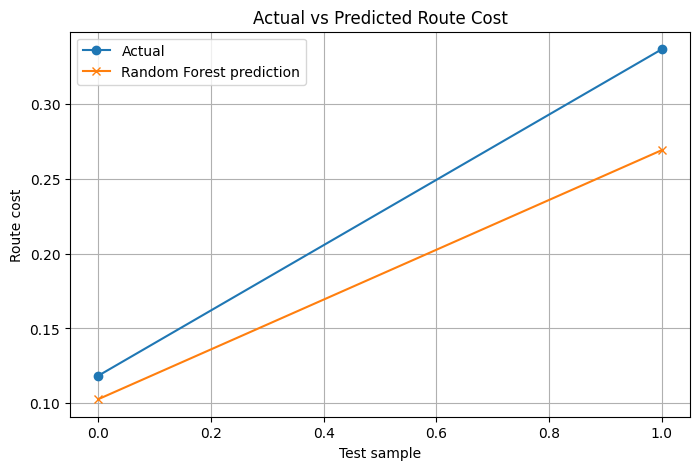

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    y_test.to_numpy(),
    marker="o",
    label="Actual"
)

plt.plot(
    range(len(y_test)),
    rf_predictions,
    marker="x",
    label="Random Forest prediction"
)

plt.xlabel("Test sample")
plt.ylabel("Route cost")
plt.title("Actual vs Predicted Route Cost")
plt.legend()
plt.grid(True)
plt.show()

## View feature importance:-by random forest

,Feature,Importance
4,throughput,0.356565
3,delay,0.269119
0,packets_sent,0.186479
1,packets_received,0.160796
5,jitter,0.027041
2,packets_lost,0.000000
6,packet_delivery_ratio_percent,0.000000


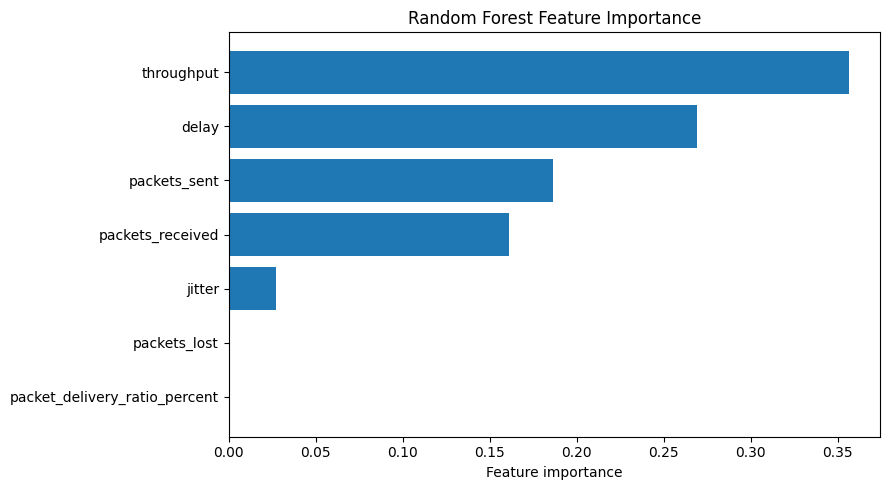

In [17]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Save the trained model

In [18]:
import os
import joblib

os.makedirs("ml", exist_ok=True)

best_name = results.loc[results["MAE"].idxmin(), "Model"]

if best_name == "Decision Tree":
    best_model = dt_model
else:
    best_model = rf_model

model_package = {
    "model": best_model,
    "model_name": best_name,
    "features": features,
    "target": "route_cost"
}

joblib.dump(model_package, "ml/route_cost_model.pkl")

print("Selected model:", best_name)
print("Model saved to ml/route_cost_model.pkl")

Selected model: Decision Tree
Model saved to ml/route_cost_model.pkl


## Load the saved model and test it

In [19]:
loaded_package = joblib.load("ml/route_cost_model.pkl")

loaded_model = loaded_package["model"]
loaded_features = loaded_package["features"]

sample = X_test[loaded_features].iloc[[0]]
prediction = loaded_model.predict(sample)[0]

print("Model:", loaded_package["model_name"])
print("Input network metrics:")
display(sample)

print("Predicted route cost:", round(float(prediction), 4))
print("Actual route cost:", round(float(y_test.iloc[0]), 4))

Model: Decision Tree
Input network metrics:


,packets_sent,packets_received,packets_lost,delay,throughput,jitter,packet_delivery_ratio_percent
7,43945,43945,0,0.02959,21.7179,0.0,100.0


Predicted route cost: 0.1184
Actual route cost: 0.1184


## Step 2: Generate candidate paths through your 10-router topology.

## Step 3: Prepare valid measurements for each candidate route.

## Step 4: Predict route costs and select a candidate.

## Step 5: Connect the decision to NS-3 and test it.